In [1]:
!pip install -q imbalanced-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler

In [4]:
uploaded = files.upload()

Saving water_potability_class_balanced.csv to water_potability_class_balanced.csv


In [5]:
file_name = 'water_potability_class_balanced.csv'

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (9362, 27)


In [6]:
df.head()

,sample_id,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,...,is_high_solids,is_high_turbidity,is_high_organic,is_high_chloramines,ph_hardness_ratio,solids_conductivity_ratio,organic_turbidity_ratio,water_quality_score,quality_grade,risk_factor_count
0,3422,10.6075,180.0693,21741.2983,6.9690,340.4020,455.4743,16.3926,33.6693,3.9449,...,1,0,1,0,0.0586,47.6287,4.0527,45,2,3
1,9212,8.4957,221.8667,24960.7647,6.1700,341.5504,388.5389,16.0741,35.9161,3.8698,...,1,0,1,0,0.0381,64.0777,4.0491,65,3,3
2,1988,7.6114,215.3860,12012.0025,11.0270,397.7865,317.4033,12.0742,58.1001,3.5904,...,0,0,0,1,0.0352,37.7257,3.2718,80,3,2
3,9989,6.4915,198.1058,18819.7433,7.3373,333.1931,256.4398,13.7740,52.5501,3.2808,...,0,0,0,0,0.0326,73.1035,4.0742,80,3,1
4,9672,5.1375,110.5500,11162.9412,5.7541,389.0479,314.6003,13.1551,81.3481,4.4753,...,0,0,0,0,0.0461,35.3705,2.8752,45,2,1


In [7]:
print("Columns in the dataset:")

for i, column in enumerate(df.columns, start=1):
    print(i, ".", column)

Columns in the dataset:
1 . sample_id
2 . ph
3 . Hardness
4 . Solids
5 . Chloramines
6 . Sulfate
7 . Conductivity
8 . Organic_carbon
9 . Trihalomethanes
10 . Turbidity
11 . Potability
12 . ph_is_normal
13 . ph_level
14 . hardness_level
15 . solids_level
16 . turbidity_level
17 . is_high_hardness
18 . is_high_solids
19 . is_high_turbidity
20 . is_high_organic
21 . is_high_chloramines
22 . ph_hardness_ratio
23 . solids_conductivity_ratio
24 . organic_turbidity_ratio
25 . water_quality_score
26 . quality_grade
27 . risk_factor_count


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9362 entries, 0 to 9361
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sample_id                  9362 non-null   int64  
 1   ph                         9362 non-null   float64
 2   Hardness                   9362 non-null   float64
 3   Solids                     9362 non-null   float64
 4   Chloramines                9362 non-null   float64
 5   Sulfate                    9362 non-null   float64
 6   Conductivity               9362 non-null   float64
 7   Organic_carbon             9362 non-null   float64
 8   Trihalomethanes            9362 non-null   float64
 9   Turbidity                  9362 non-null   float64
 10  Potability                 9362 non-null   int64  
 11  ph_is_normal               9362 non-null   int64  
 12  ph_level                   9362 non-null   int64  
 13  hardness_level             9362 non-null   int64

In [9]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
sample_id                    0
ph                           0
Hardness                     0
Solids                       0
Chloramines                  0
Sulfate                      0
Conductivity                 0
Organic_carbon               0
Trihalomethanes              0
Turbidity                    0
Potability                   0
ph_is_normal                 0
ph_level                     0
hardness_level               0
solids_level                 0
turbidity_level              0
is_high_hardness             0
is_high_solids               0
is_high_turbidity            0
is_high_organic              0
is_high_chloramines          0
ph_hardness_ratio            0
solids_conductivity_ratio    0
organic_turbidity_ratio      0
water_quality_score          0
quality_grade                0
risk_factor_count            0
dtype: int64


In [10]:
print(df["quality_grade"].value_counts().sort_index())

quality_grade
1    2286
2    3733
3    2851
4     492
Name: count, dtype: int64


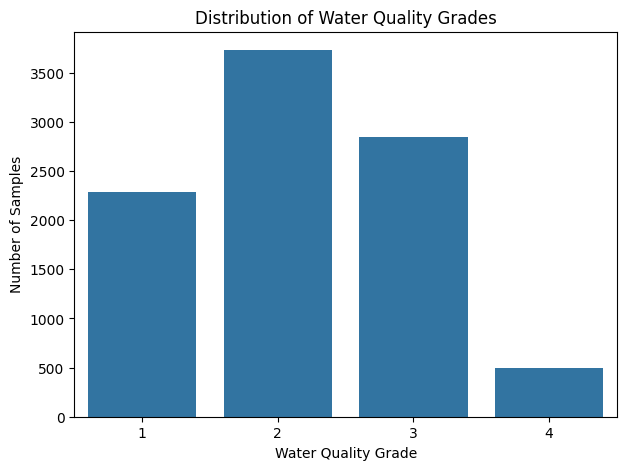

In [11]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="quality_grade",
    data=df
)

plt.title("Distribution of Water Quality Grades")
plt.xlabel("Water Quality Grade")
plt.ylabel("Number of Samples")

plt.show()

In [12]:
X = df.drop(
    columns=[
        "quality_grade",
        "sample_id",
        "water_quality_score",
        "risk_factor_count"
    ]
)

y = df["quality_grade"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (9362, 23)
Target shape: (9362,)


In [13]:
print("Features used for training:")

for column in X.columns:
    print(column)

Features used for training:
ph
Hardness
Solids
Chloramines
Sulfate
Conductivity
Organic_carbon
Trihalomethanes
Turbidity
Potability
ph_is_normal
ph_level
hardness_level
solids_level
turbidity_level
is_high_hardness
is_high_solids
is_high_turbidity
is_high_organic
is_high_chloramines
ph_hardness_ratio
solids_conductivity_ratio
organic_turbidity_ratio


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7489, 23)
Testing data: (1873, 23)


In [15]:
print("Training class distribution BEFORE balancing:")

print(y_train.value_counts().sort_index())

Training class distribution BEFORE balancing:
quality_grade
1    1829
2    2986
3    2281
4     393
Name: count, dtype: int64


In [16]:
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train,
    y_train
)

In [17]:
print("Training class distribution AFTER balancing:")

print(y_train_balanced.value_counts().sort_index())

Training class distribution AFTER balancing:
quality_grade
1    2986
2    2986
3    2986
4    2986
Name: count, dtype: int64


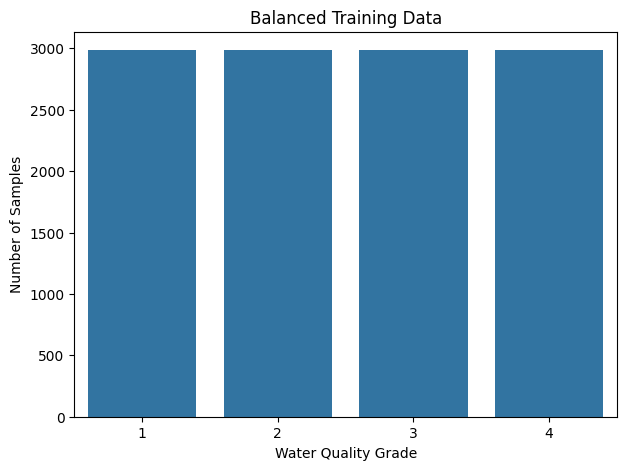

In [18]:
plt.figure(figsize=(7,5))

sns.countplot(
    x=y_train_balanced
)

plt.title("Balanced Training Data")
plt.xlabel("Water Quality Grade")
plt.ylabel("Number of Samples")

plt.show()

In [19]:
results = []

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", "="*50)
    print(model_name)
    print("="*50)

    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1 Score :", round(f1 * 100, 2), "%")

In [20]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_balanced,
    y_train_balanced
)

rf_pred = rf_model.predict(X_test)

evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)


Random Forest
Accuracy : 97.76 %
Precision: 97.77 %
Recall   : 97.76 %
F1 Score : 97.76 %


In [21]:
print(classification_report(
    y_test,
    rf_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           1       0.99      0.97      0.98       457
           2       0.97      0.98      0.98       747
           3       0.98      0.98      0.98       570
           4       0.98      0.94      0.96        99

    accuracy                           0.98      1873
   macro avg       0.98      0.97      0.97      1873
weighted avg       0.98      0.98      0.98      1873



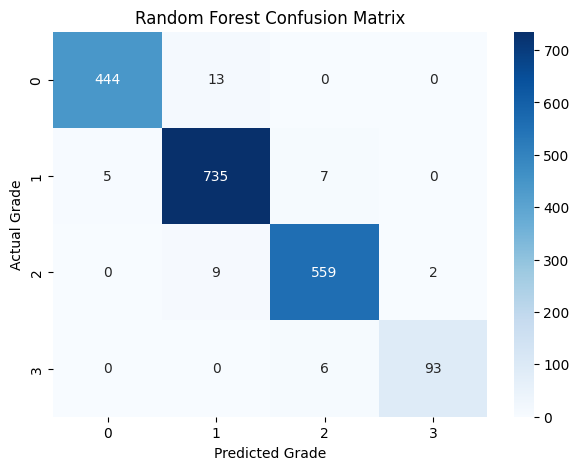

In [23]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")

plt.show()

Logistic regression


In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_balanced)

X_test_scaled = scaler.transform(X_test)

In [25]:
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_model.fit(
    X_train_scaled,
    y_train_balanced
)

lr_pred = lr_model.predict(X_test_scaled)

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred
)


Logistic Regression
Accuracy : 79.5 %
Precision: 79.81 %
Recall   : 79.5 %
F1 Score : 79.48 %


decision tree



In [26]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train_balanced,
    y_train_balanced
)

dt_pred = dt_model.predict(X_test)

evaluate_model(
    "Decision Tree",
    y_test,
    dt_pred
)


Decision Tree
Accuracy : 96.58 %
Precision: 96.59 %
Recall   : 96.58 %
F1 Score : 96.58 %


KNN



In [27]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train_balanced
)

knn_pred = knn_model.predict(X_test_scaled)

evaluate_model(
    "KNN",
    y_test,
    knn_pred
)


KNN
Accuracy : 84.78 %
Precision: 84.88 %
Recall   : 84.78 %
F1 Score : 84.76 %


svm




In [28]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train_balanced
)

svm_pred = svm_model.predict(X_test_scaled)

evaluate_model(
    "SVM",
    y_test,
    svm_pred
)


SVM
Accuracy : 91.3 %
Precision: 91.49 %
Recall   : 91.3 %
F1 Score : 91.32 %


gradiant boosting

In [29]:
gb_model = GradientBoostingClassifier(
    random_state=42
)

gb_model.fit(
    X_train_balanced,
    y_train_balanced
)

gb_pred = gb_model.predict(X_test)

evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_pred
)


Gradient Boosting
Accuracy : 94.66 %
Precision: 94.68 %
Recall   : 94.66 %
F1 Score : 94.66 %


In [30]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.977576,0.977663,0.977576,0.977561
1,Logistic Regression,0.794981,0.798073,0.794981,0.794784
2,Decision Tree,0.965830,0.965877,0.965830,0.965834
3,KNN,0.847838,0.848779,0.847838,0.847645
4,SVM,0.912974,0.914851,0.912974,0.913244
5,Gradient Boosting,0.946610,0.946804,0.946610,0.946599


In [31]:
results_percentage = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_percentage[metric_columns] = (
    results_percentage[metric_columns] * 100
)

results_percentage

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,97.757608,97.766299,97.757608,97.756119
1,Logistic Regression,79.498131,79.807321,79.498131,79.478433
2,Decision Tree,96.583022,96.587685,96.583022,96.583358
3,KNN,84.783769,84.877898,84.783769,84.764457
4,SVM,91.297384,91.485112,91.297384,91.324423
5,Gradient Boosting,94.660972,94.680357,94.660972,94.659930


accuarcy

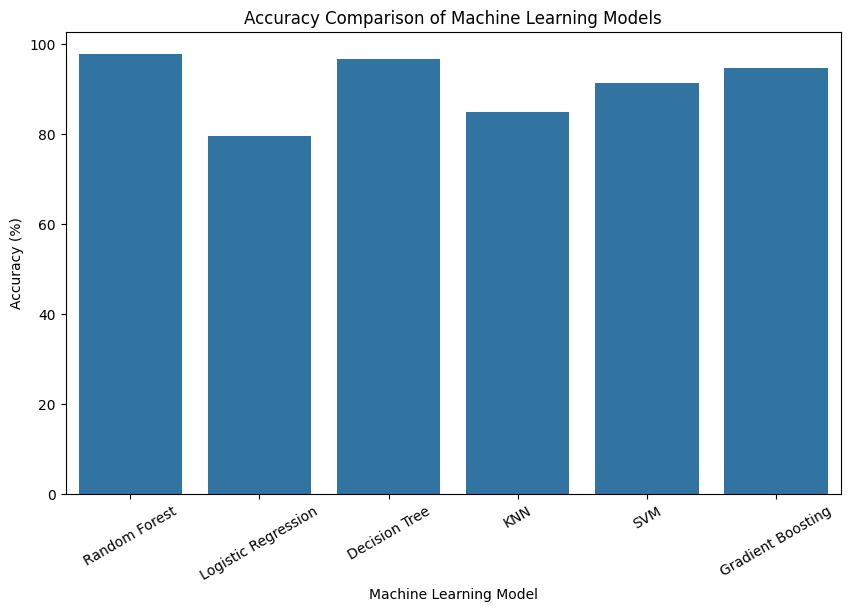

In [32]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Model",
    y="Accuracy",
    data=results_percentage
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=30)

plt.show()

precision

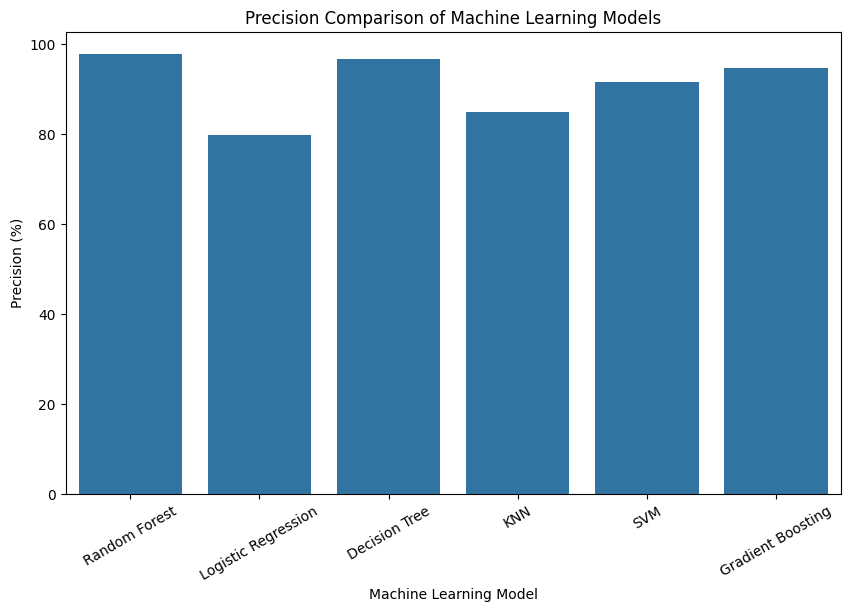

In [33]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Model",
    y="Precision",
    data=results_percentage
)

plt.title("Precision Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Precision (%)")

plt.xticks(rotation=30)

plt.show()

recall



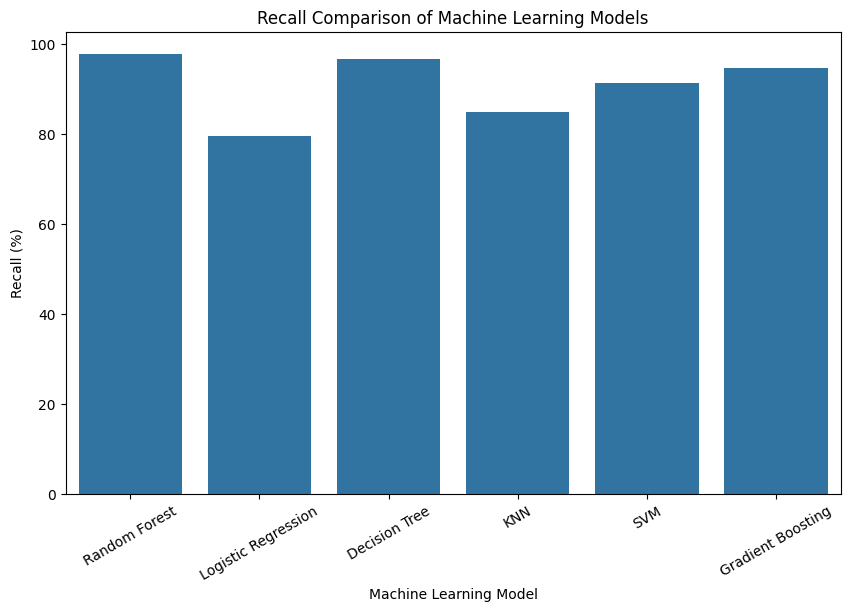

In [34]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Model",
    y="Recall",
    data=results_percentage
)

plt.title("Recall Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Recall (%)")

plt.xticks(rotation=30)

plt.show()

f1 score


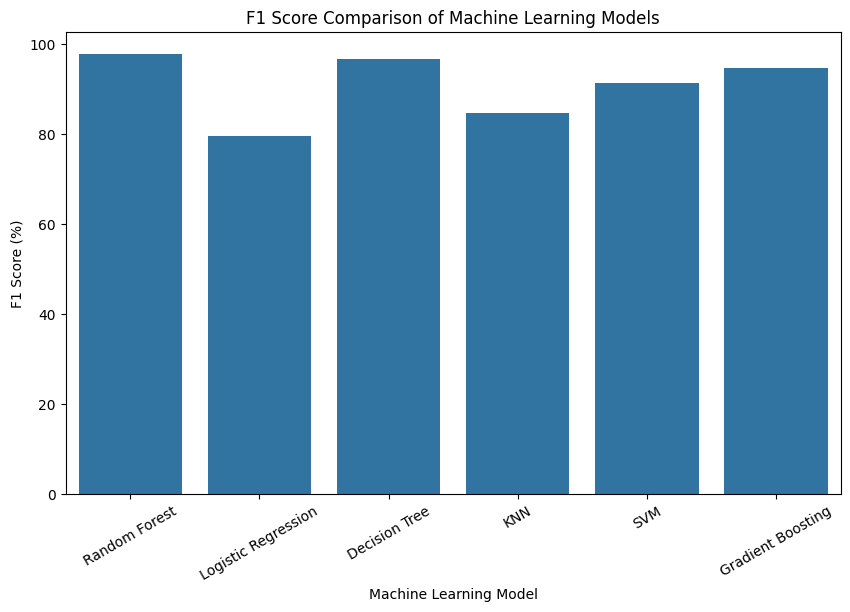

In [35]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Model",
    y="F1 Score",
    data=results_percentage
)

plt.title("F1 Score Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score (%)")

plt.xticks(rotation=30)

plt.show()

all results


In [36]:
results_percentage.round(2)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,97.76,97.77,97.76,97.76
1,Logistic Regression,79.50,79.81,79.50,79.48
2,Decision Tree,96.58,96.59,96.58,96.58
3,KNN,84.78,84.88,84.78,84.76
4,SVM,91.30,91.49,91.30,91.32
5,Gradient Boosting,94.66,94.68,94.66,94.66


saving


In [37]:
results_percentage.to_csv(
    "water_quality_model_comparison.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [38]:
files.download("water_quality_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Feature Importance


In [39]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
8,Turbidity,0.104511
5,Conductivity,0.095644
10,ph_is_normal,0.093539
6,Organic_carbon,0.076137
1,Hardness,0.062046
0,ph,0.061415
3,Chloramines,0.059531
7,Trihalomethanes,0.051797
2,Solids,0.048139
22,organic_turbidity_ratio,0.045356


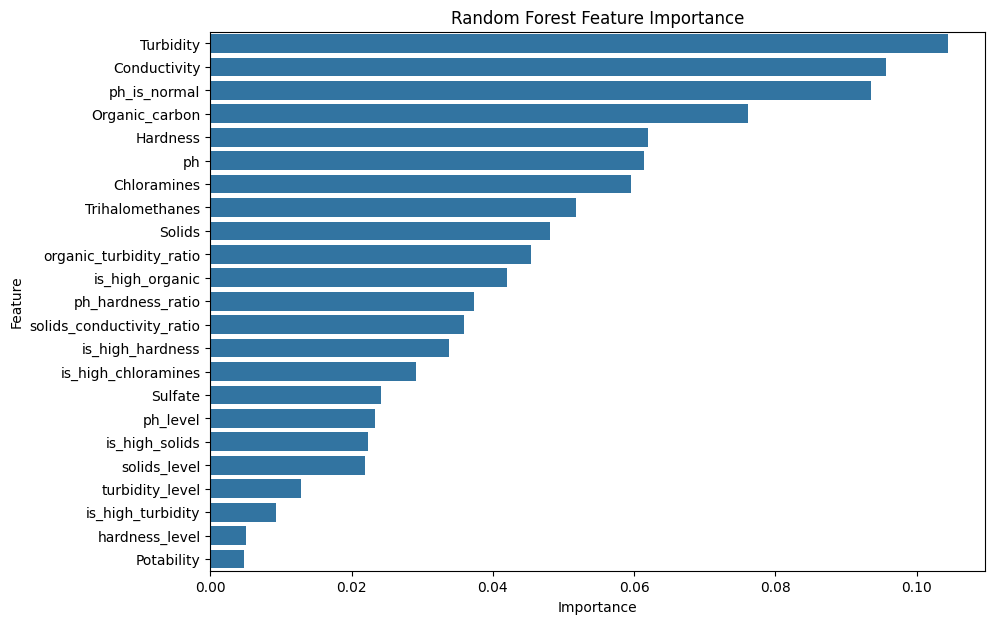

In [40]:
plt.figure(figsize=(10,7))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [41]:
feature_importance.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

print("Feature importance saved!")

Feature importance saved!
